# DiT layer looping — team notebook for Colab / GCP

This notebook is a thin driver: **all functions live in packages**. Shared sampling, evaluation, metrics, reporting and run preparation are in **`team_pipeline/`**; the XSA method, block schedules and method runner are in **`xsa_method/`**. The notebook only sets up the environment, imports them, holds configuration, and calls them. Run from this project checkout locally. In Colab, section 1 can clone the project; set `PROJECT_REF` to a branch or commit containing `team_pipeline/runs.py`, or upload the updated project. The official DiT source and pretrained weights still require internet downloads.

**Run guide:** select the repository `venv` kernel locally, or a CUDA GPU runtime in Colab, then run sections **1–8 in order** for the shared validation experiment. Section 2 only imports and sets constants; the actual experiment runs in sections 5–8. Optional custom methods (9), held-out testing (10), and export (11) have separate cells. Held-out testing is disabled until explicitly enabled. Section 12 can be run on its own after sections 1 and 2.

| Section / cell label | Action | GPU inference? |
| --- | --- | --- |
| 1 · SETUP | Workspace, optional Drive storage, dependencies | No |
| 2 · IMPORTS | Package imports and protocol constants | No |
| 3 · RUN TESTS | Tiny CPU contract and artifact tests | No |
| 4 · CONFIGURE | Automatic CUDA / Apple MPS / CPU selection, pinned DiT source | No |
| 5 · RUN PREPARE | Checkpoint download, hashes, environment recording | No |
| 6 · SELECT BLOCKS | Fixed `[4, 7]` by default; optional calibration | Optional |
| 7A–7E · RUN VALIDATION | Original, removal, looping, damped looping, XSA reuse | Yes |
| 8 · RUN EVALUATION | Paired LPIPS, Imagenette FID, CSVs and grid; TPIPS off | CPU by default |
| 9 · OPTIONAL CUSTOM | Example member method and evaluation | Yes |
| 10 · RUN HELD-OUT TEST | Frozen choices on fresh test seeds | Yes |
| 11 · EXPORT | Archive a run for sharing | No |
| 12 · REPORT | Tables and figures from saved runs | No |

The protocol uses the **ten Imagenette classes** from `CLASS_LABELS` (`team_pipeline/data.py`): **20 calibration, 20 validation and 300 held-out test images per method**, 50 sampling steps, FP32 and fixed seeds. Calibration is skipped with fixed block selection. Imagenette has more real training images per class on average than Imagewoof (946.9 versus 902.5), and a higher minimum class count (858 versus 580). Final evaluation is deliberately disabled until settings are frozen; at the measured MPS rate, all five final methods take roughly 53 hours of sampling. No model training is performed; Imagenette training-split images supply the real FID reference. Use validation to choose settings; keep test inputs held out. LPIPS measures agreement with the original outputs, not generative quality or FID.

**Collaboration:** notebook edits are shared; each runtime has its own Python state and files. Each member should use a distinct run name/output directory. Compare methods within the same recorded environment and hardware. Download artifacts before a temporary runtime ends, or enable Drive storage in section 1.

## 1. SETUP — workspace and dependencies

Run once per fresh runtime. Keep the runtime’s CUDA-compatible PyTorch/torchvision pair. If pip requests a runtime restart, restart and rerun from here. Drive mounting is optional; source stays in the working directory and outputs can be stored on Drive.

In [1]:
# SETUP — no experiment starts here.
import importlib
from pathlib import Path
import subprocess
import sys

WORKSPACE = Path.cwd()
USE_GOOGLE_DRIVE = False
if USE_GOOGLE_DRIVE:
    drive = importlib.import_module("google.colab.drive")
    drive.mount("/content/drive")
OUTPUT_BASE = (Path("/content/drive/MyDrive/DiT_team_runs")
               if USE_GOOGLE_DRIVE else WORKSPACE / "team_runs")
subprocess.run([sys.executable, "-m", "pip", "install",
                "timm", "diffusers", "accelerate", "lpips", "numpy", "transformers>=4.50,<5",
                "pandas", "matplotlib", "pillow", "pytest", "huggingface_hub"], check=True)
print("Source workspace:", WORKSPACE)
print("Output base:", OUTPUT_BASE)

# Local checkout: use this project directly. Colab: clone the project once.
PROJECT_URL = "https://github.com/cl-xy/cs5787-deep-learning.git"
PROJECT_REF = "milestone-check"  # Set to the branch/commit containing team_pipeline/runs.py.
PROJECT_MARKER = "team_pipeline/runs.py"
PROJECT_ROOT = WORKSPACE
if not (PROJECT_ROOT / PROJECT_MARKER).is_file():
    PROJECT_ROOT = WORKSPACE / "cs5787-deep-learning"
    if not PROJECT_ROOT.exists():
        subprocess.run(["git", "clone", PROJECT_URL, str(PROJECT_ROOT)], check=True)
        subprocess.run(["git", "-C", str(PROJECT_ROOT), "checkout", PROJECT_REF], check=True)
    if not (PROJECT_ROOT / PROJECT_MARKER).is_file():
        raise FileNotFoundError(
            f"{PROJECT_MARKER} is missing. Set PROJECT_REF to the ref containing the "
            "refactor and check out that ref in PROJECT_ROOT, or upload the updated project."
        )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Pipeline source:", PROJECT_ROOT / "team_pipeline")
print("Method source:", PROJECT_ROOT / "xsa_method")

Source workspace: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning
Output base: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/team_runs
Pipeline source: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/team_pipeline
Method source: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/xsa_method



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


## 2. IMPORTS — shared pipeline and XSA method

No functions are defined in this notebook. The next cell imports them from `team_pipeline/` and `xsa_method/`; the following cell sets the protocol constants.

Importing runs no inference. `team_pipeline` is imported before `torch` because it sets `CUBLAS_WORKSPACE_CONFIG` and `PYTORCH_ENABLE_MPS_FALLBACK` (in one place, `team_pipeline/__init__.py`). After editing package code, **restart the kernel** and rerun sections 1–4 before preparing a **new run**: the run fingerprint is a copy of the package sources taken when they were imported, so editing a file without restarting never changes the fingerprint of the code actually running. Runs prepared before this refactor cannot be resumed (their fingerprint covered notebook cells), but section 12 can still plot their saved artifacts.

### 2.1. IMPORT — package functions

In [2]:
# IMPORTS — team_pipeline first: it sets the PyTorch environment variables.
from datetime import datetime, timezone
from functools import partial
import importlib
import json
from pathlib import Path
import shutil
import subprocess
import sys
from types import SimpleNamespace

from team_pipeline.data import CLASS_LABELS, load_protocol, make_protocol
from team_pipeline.evaluation import evaluate_split
from team_pipeline.example_method import build_model
from team_pipeline.extended_metrics import evaluate_saved_split
from team_pipeline.notebook import (run_methods, show_evaluation, show_figure_paths,
                                    show_image)
from team_pipeline.profiling import summarize_profile
from team_pipeline.report import (REPORT_PLOTS, find_report_run, load_report_data,
                                  plot_report_samples)
from team_pipeline.runs import load_run, prepare
from team_pipeline.runtime import pip_install, select_device
from team_pipeline.sampling import calibrate, run_variant
from xsa_method import (ScheduledBlocks, bind_runner, load_fixed_selection,
                        write_fixed_selection)

import pandas as pd
import torch
from IPython.display import display

### 2.2. PROTOCOL — Imagenette sample counts, custom-method settings

In [3]:
# PROTOCOL — sample counts per class; class ids come from team_pipeline.data.
CALIBRATION_IMAGES_PER_CLASS = 2
VALIDATION_IMAGES_PER_CLASS = 2  # 20 images/method for selecting settings.
FINAL_IMAGES_PER_CLASS = 30    # 300 images/method in the held-out test.
FID_REAL_IMAGES_PER_CLASS = 500  # Balanced, fixed real reference: 5,000 images.

PROTOCOL = make_protocol(
    labels=CLASS_LABELS,
    calibration_per_class=CALIBRATION_IMAGES_PER_CLASS,
    validation_per_class=VALIDATION_IMAGES_PER_CLASS,
    test_per_class=FINAL_IMAGES_PER_CLASS,
)
CUSTOM_SETTINGS = {"removed": [4], "mode": "damped", "alpha": "inverse_k"}
print("ImageNet class ids:", list(CLASS_LABELS))
print("Images per split:", {key: len(value) for key, value in PROTOCOL["splits"].items()})

ImageNet class ids: [0, 217, 482, 491, 497, 566, 569, 571, 574, 701]
Images per split: {'calibration': 20, 'validation': 20, 'test': 300}


## 3. RUN TESTS — shared pipeline and XSA package

Runs `tests_team/` and `tests_xsa/` with tiny CPU models: protocol and input validation, deterministic seeding, runner and evaluator mismatch checks, custom-builder freezing, XSA attention, inverse-k damping, checkpoint restoration, report generation and the notebook contract. No pretrained downloads are needed. Stop if any check fails.

In [4]:
# RUN TESTS — CPU only; no pretrained downloads.
# This running notebook has outputs; leave the clean-source check to the CLI suite.
subprocess.run(
    [sys.executable, "-m", "pytest", "--import-mode=importlib", "-q", "tests_team", "tests_xsa",
     "--deselect=tests_xsa/test_notebook.py::test_notebook_is_saved_without_outputs"],
    cwd=PROJECT_ROOT, check=True,
)

........................................................................ [ 51%]
......................................ss.............................    [100%]
=============================== warnings summary ===============================
tests_team/test_xsa.py::test_imagenet_reference_build_reuse_and_fid
tests_team/test_xsa.py::test_imagenet_reference_build_reuse_and_fid
tests_team/test_xsa.py::test_imagenet_reference_build_reuse_and_fid
tests_team/test_xsa.py::test_imagenet_reference_build_reuse_and_fid
tests_team/test_xsa.py::test_imagenet_reference_build_reuse_and_fid
  /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/team_pipeline/extended_metrics.py:264: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
    covmean = linalg.sqrtm(s1.dot(s2))

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
139 passed, 2 skipped, 1 deselected, 5 warnings in 28.42s


CompletedProcess(args=['/Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/bin/python', '-m', 'pytest', '--import-mode=importlib', '-q', 'tests_team', 'tests_xsa', '--deselect=tests_xsa/test_notebook.py::test_notebook_is_saved_without_outputs'], returncode=0)

## 4. CONFIGURE — device, source and experiment settings

Run after tests pass. `DEVICE="auto"` selects CUDA, then Apple MPS, then CPU; you can explicitly choose `"cuda:0"`, `"mps"` or `"cpu"`. Full DiT-XL inference on CPU is slow. The DiT checkpoint download is about 2.5 GiB, and the VAE is downloaded on first generation.

Choose a unique member/run name. The XSA comparison defaults to fixed zero-based block indices `[4, 7]` for every compressed method. Set `CALIBRATE_BLOCKS=True` to select blocks by calibration instead. Re-running this cell creates a new run path unless `RESUME_RUN` is set. **Create a new run for the Imagenette class protocol; existing eight-class outputs cannot be mixed with it.** After changing shared code, use a new run for generation. To plot existing results without inference or environment checks, run section 12 directly. To evaluate compatible existing outputs, set `RESUME_RUN` here, then run section 8; generation cells must not be rerun for completed variants.


In [5]:
# CONFIGURE — does not generate images.

DEVICE = "auto"
RESUME_RUN = None  # Leave None for the new Imagenette protocol; old eight-class runs differ.
CALIBRATE_BLOCKS = False
FIXED_REMOVED = [4, 7]  # Zero-based, shared by removal / loop / damped / XSA.
REMOVE_COUNT = 2  # Used only when CALIBRATE_BLOCKS=True.

protocol = load_protocol(PROTOCOL)
REPO = WORKSPACE / "third_party/DiT"
if not (REPO / "models.py").is_file():
    REPO.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(["git", "clone", "https://github.com/facebookresearch/DiT.git", str(REPO)], check=True)
subprocess.run(["git", "-C", str(REPO), "checkout", "--detach", protocol["settings"]["dit_commit"]], check=True)
MEMBER = "team"  # Use your name for independent runs.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_ROOT = (Path(RESUME_RUN).expanduser().resolve() if RESUME_RUN
            else OUTPUT_BASE / f"{MEMBER}_{RUN_ID}")
CHECKPOINT = WORKSPACE / "checkpoints/DiT-XL-2-256x256.pt"
ALPHA = "inverse_k"  # Reused calls use 1/2, 1/3, ...; original call counts as k=1.
KEEP_CHECKPOINTS = False  # True retains several GB per variant.
# (method, run-folder name, extra run arguments); used by sections 7, 8 and 10.
METHODS = [
    ("original", "original", {}),
    ("removal", "member1_removal", {}),
    ("loop", "member2_loop", {}),
    ("damped", "member3_damped", {"alpha": ALPHA}),
    ("xsa_reuse", "member4_xsa_reuse", {"alpha": 1.0}),
]
NAMES = [name for _method, name, _kwargs in METHODS]

if RESUME_RUN:
    saved_config = json.loads((RUN_ROOT / "config.json").read_text())
    DEVICE = saved_config["device"]
    CHECKPOINT = Path(saved_config["checkpoint"])
device = select_device(DEVICE)
RUN_ARGS = SimpleNamespace(output=RUN_ROOT, repo=REPO, protocol=PROTOCOL,
                           device=str(device), checkpoint=CHECKPOINT)
# Bind the run and the shared pipeline once; run_method(split, method, name, ...) needs no globals.
run_method = bind_runner(
    RUN_ARGS, load_run=load_run, keep_checkpoints=KEEP_CHECKPOINTS,
    run_variant=partial(run_variant, schedule_cls=ScheduledBlocks),
)

print("Device:", device, "| PyTorch:", torch.__version__)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(device))
print("Run directory:", RUN_ROOT)
print("ImageNet class ids:", list(CLASS_LABELS))
print("Images per split:", {key: len(value) for key, value in protocol["splits"].items()})

Device: mps | PyTorch: 2.14.1
Run directory: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/team_runs/team_20261126T040521152748Z
ImageNet class ids: [0, 217, 482, 491, 497, 566, 569, 571, 574, 701]
Images per split: {'calibration': 20, 'validation': 20, 'test': 300}


HEAD is now at ed81ce2 Update README.md


## 5. RUN PREPARE — freeze shared inputs

Downloads the pretrained DiT checkpoint if needed and verifies its SHA-256. Records protocol, shared-code hash, environment and package versions. Requires a **new** output directory; skip this cell when resuming an already prepared run.

In [6]:
# RUN PREPARE — skip downloading/preparing again when resuming.
if RESUME_RUN:
    load_run(RUN_ARGS)  # Verify the saved code, environment and inputs.
    print("Resumed:", RUN_ROOT)
else:
    prepare(RUN_ARGS)

/Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 2.52G/2.52G [01:09<00:00, 39.1MB/s]


Prepared shared inputs: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/team_runs/team_20261126T040521152748Z


## 6. SELECT BLOCKS — fixed selection or optional calibration

The default XSA comparison uses fixed zero-based indices `[4, 7]`, so no calibration inference is required. All compressed methods use the same saved selection. To rank blocks by hidden-state change instead, set `CALIBRATE_BLOCKS=True` in section 4. A saved selection is frozen for the run; use a new run to change it.


In [ ]:
# SELECT BLOCKS — fixed indices avoid calibration inference by default.
root, protocol, config = load_run(RUN_ARGS)
selection_path = root / "profile/selection.json"
if selection_path.exists():
    selection = load_fixed_selection(root)
elif CALIBRATE_BLOCKS:
    profile = calibrate(config, protocol["splits"]["calibration"], root / "profile")
    summarize_profile(profile, root / "profile", REMOVE_COUNT)
    selection = load_fixed_selection(root)
else:
    selection = write_fixed_selection(root, FIXED_REMOVED)
print("Selection:", selection)
heatmap = root / "profile/feature_change_heatmap.png"
if heatmap.exists():
    show_image(heatmap)

## 7. RUN VALIDATION — one cell per method

Run 7A–7E after preparation and block selection. Each cell loads its own model, generates the same 20 validation samples (two per Imagenette class), saves tensors/images and measurements, then releases the model. The first generation downloads the pinned VAE.

Each method grid previews at most 16 images; all samples are still saved individually for metrics. Existing variant directories are never overwritten. If a cell fails, inspect and rename its partial folder before retrying, or start a new run in section 4. Do not rerun completed methods simply to evaluate them again.

Removal skips selected slots. Looping reuses the nearest preceding retained block; damped looping applies `h + (B(h,c) - h) / k` at replacement slots, where `k` is the call index of that retained source block (original call is `k=1`). The first, second and third extra calls use `1/2`, `1/3` and `1/4`; counting starts over for each retained block and each model forward. With `[4, 7]`, each reused block has only one extra call, so both scales remain `1/2`. Numeric alpha values remain supported for loading and comparing older fixed-alpha runs. Reused weights are stored once. XSA reuse also reuses the preceding retained block and filters its self-value direction at replacement slots. Looping reduces unique weights but does not promise lower latency.

### 7A. RUN VALIDATION — original baseline

In [ ]:
# RUN VALIDATION — original baseline
run_methods(run_method, RUN_ROOT, "validation", METHODS, only="original")

### 7B. RUN VALIDATION — member 1: removal

In [ ]:
# RUN VALIDATION — member 1: removal
run_methods(run_method, RUN_ROOT, "validation", METHODS, only="member1_removal")

### 7C. RUN VALIDATION — member 2: looping

In [ ]:
# RUN VALIDATION — member 2: looping
run_methods(run_method, RUN_ROOT, "validation", METHODS, only="member2_loop")

### 7D. RUN VALIDATION — member 3: damped looping



In [ ]:
# RUN VALIDATION — member 3: damped looping
run_methods(run_method, RUN_ROOT, "validation", METHODS, only="member3_damped")

### 7E. RUN VALIDATION — member 4: XSA reuse


In [ ]:
# RUN VALIDATION — member 4: XSA reuse
run_methods(run_method, RUN_ROOT, "validation", METHODS, only="member4_xsa_reuse")

## 8. RUN EVALUATION — LPIPS, CLIP and optional Imagenette FID

Run after all five validation methods finish. `evaluate_saved_split` (in `team_pipeline/extended_metrics.py`) computes LPIPS and the enabled CLIP/FID/TPIPS metrics. LPIPS runs on CPU. The real FID reference is **500 images from each of the ten Imagenette classes**, sampled deterministically from the dataset's training split. This does not train DiT. The full-resolution Imagenette v2 archive is about **1.45 GiB**; torchvision downloads it directly from fast.ai once and verifies its checksum. No full ImageNet download or Hugging Face login is needed. Keep both the extracted source and prepared reference for reuse.

The prepared reference contains RGB PNGs center-cropped/resized to 256x256, with class ids, original filenames, selection seed and preprocessing recorded in `reference_manifest.json`. The same balanced reference is reused across all methods and the held-out test. The dataset's local labels 0–9 are never passed to DiT; generation uses the original ImageNet ids in `CLASS_LABELS`.

**Validation has only 20 generated images per method, so its FID is an exploratory diagnostic.** Section 10 runs 300 held-out images per method and, when FID is enabled, evaluates them against the same 5,000 real references. Report the dataset/subset, counts and preprocessing, and check sampling variability; this is not the published full-ImageNet FID-50K benchmark.

TPIPS stays disabled (`TPIPS_FACTORS=()`). Set `ENABLE_FID=False` and `ENABLE_CLIP=False` for LPIPS only. Timing excludes model loading, warmup, saving and all evaluation/reference preparation.
FID is off by default (`ENABLE_FID=False`); this skips reference downloads, preparation and FID computation. CLIP is enabled (`ENABLE_CLIP=True`) independently of FID. It reports raw image–text cosine against `a photo of a {ImageNet class name}` and image–image cosine against the original image with the same class and seed. Higher is better for both. Means/sample SDs are saved in `results_extended.csv`, per-image scores in `paired_metrics_extended.csv`. First use downloads CLIP ViT-B/32 weights/tokenizer. Set `ENABLE_CLIP=False` to skip it. Rerun the metric settings and evaluation cells after changing flags.


In [ ]:
# METRIC SETTINGS — CLIP enabled; FID and TPIPS opt-in.
ENABLE_FID = False
ENABLE_CLIP = True
CLIP_DEVICE = "cpu"
CLIP_BATCH_SIZE = 16
USE_IMAGENETTE_REFERENCE = True
IMAGENETTE_SOURCE_ROOT = WORKSPACE / "fid_references" / "source"
IMAGENETTE_PREPARED_ROOT = WORKSPACE / "fid_references" / "prepared"
FID_REFERENCE_DIR = None  # Or a folder of real images for an existing reference.
FID_REFERENCE_DESCRIPTION = None
TPIPS_FACTORS = ()  # No TPIPS package/weights are loaded with this default.
FID_DEVICE = "cpu"
TPIPS_DEVICE = str(select_device("auto"))

# Arguments shared by the validation (section 8) and held-out test (section 10) evaluations.
EVAL_OPTIONS = dict(
    enable_fid=ENABLE_FID, enable_clip=ENABLE_CLIP,
    clip_device=CLIP_DEVICE, clip_batch_size=CLIP_BATCH_SIZE,
    imagenette_source_root=IMAGENETTE_SOURCE_ROOT if USE_IMAGENETTE_REFERENCE else None,
    imagenette_prepared_root=IMAGENETTE_PREPARED_ROOT,
    fid_real_images_per_class=FID_REAL_IMAGES_PER_CLASS,
    fid_reference_dir=FID_REFERENCE_DIR,
    fid_reference_description=FID_REFERENCE_DESCRIPTION,
    tpips_factors=TPIPS_FACTORS, fid_device=FID_DEVICE, tpips_device=TPIPS_DEVICE,
    # Optional metric packages are installed here, after the base LPIPS checks pass.
    installer=lambda packages: pip_install([*packages, "scipy<1.18"]),
)

In [ ]:
# RUN EVALUATION — works for validation now and the larger held-out test later.
# `protocol` was loaded from the prepared run in section 6.
outcome = evaluate_saved_split(RUN_ROOT, protocol, "validation", NAMES, **EVAL_OPTIONS)
show_evaluation(outcome)
results = outcome["results"]

In [ ]:
print("Saved run:", RUN_ROOT)

To reopen a saved run, set `RESUME_RUN` in section 4. This keeps `RUN_ROOT` and `RUN_ARGS.output` aligned.


## 9. OPTIONAL CUSTOM — team member extension

Edit `build_model(model, settings)` in `team_pipeline/example_method.py` (or write your own builder in a new notebook cell) and `CUSTOM_SETTINGS` in section 2.2. The shared runner handles sampling and evaluation. The example settings are illustrative, not validation-selected. Enable this cell to run the example and compare it with the baseline. Use a new method name for every configuration.

In [ ]:
# OPTIONAL CUSTOM — disabled by default.
RUN_CUSTOM = False
CUSTOM_NAME = "custom_example"
if RUN_CUSTOM:
    run_method("validation", "custom", CUSTOM_NAME,
               builder=build_model, settings=CUSTOM_SETTINGS)
    custom_outcome = evaluate_saved_split(
        RUN_ROOT, protocol, "validation", [*NAMES, CUSTOM_NAME], **EVAL_OPTIONS)
    show_evaluation(custom_outcome)
else:
    print("Skipped custom method; set RUN_CUSTOM=True to run it.")

## 10. RUN HELD-OUT TEST — frozen Imagenette methods

Enable only after choosing settings on validation. With `FINAL_IMAGES_PER_CLASS=30` in section 2.2, this generates **300 images per method** (30 per each of the ten Imagenette classes) for the original, removal, looping, damped looping and XSA methods. At the current MPS timings, generation across five methods is approximately **3.2 hours**, plus saving, loading and evaluation. FP32 image tensors across the five methods occupy about **1.1 GiB**, plus PNGs and reference files.

Run the section 8 settings cell first: it defines `EVAL_OPTIONS`, which this section reuses. The reusable real reference is prepared the first time section 8 evaluates. Final evaluation saves LPIPS, FID, CSVs and a small comparison grid, with TPIPS disabled by default. Test seeds are disjoint from calibration and validation. Do not tune on test outputs. This does not automatically include optional custom methods.

In [ ]:
# RUN HELD-OUT TEST — enable only after validation choices are frozen.
# Default: 30 images/class x 10 classes = 300 images for EACH of five methods.
# Set FINAL_IMAGES_PER_CLASS in section 2.2 BEFORE preparing a new run.
RUN_HELD_OUT_TEST = False
if RUN_HELD_OUT_TEST:
    run_methods(run_method, RUN_ROOT, "test", METHODS, show=False)
    test_outcome = evaluate_saved_split(RUN_ROOT, protocol, "test", NAMES, **EVAL_OPTIONS)
    show_evaluation(test_outcome)
else:
    print("Skipped held-out testing; freeze validation choices before enabling.")
    print("Final images per method:", len(PROTOCOL["splits"]["test"]))

## 11. EXPORT — save and share artifacts

The run root contains protocol/config/environment records and the package freeze; `profile/` contains calibration records and selections; `validation/` and `test/` contain method manifests, samples, PNGs, FP32 tensors and comparison CSVs. Archive before a temporary runtime ends. Retained checkpoints make archives large. The imported package sources are saved as `code_sources.json` during preparation; custom builder sources are recorded in their manifests. Also save the notebook to preserve your complete edits.

In [ ]:
# EXPORT — optional; no inference.
EXPORT_RUN = False
if EXPORT_RUN:
    archive = shutil.make_archive(str(RUN_ROOT), "zip", root_dir=RUN_ROOT.parent,
                                  base_dir=RUN_ROOT.name)
    print("Archive:", archive)
    if "google.colab" in sys.modules:
        files = importlib.import_module("google.colab.files")
        files.download(archive)
else:
    print("Set EXPORT_RUN=True to archive:", RUN_ROOT)


## 12. REPORT — plots and tables from completed saved runs

Run this section **on its own** (after sections 1 and 2) to prepare existing results for the report. It does not generate images, download weights, rerun LPIPS/FID/TPIPS, or call `load_run`, so an old run remains reportable after changing the generation code. The default selects the current completed run, or the latest completed run under `team_runs`. You can set `REPORT_RUN_ROOT` and `REPORT_SPLIT` explicitly.

Figures use the recorded samples and manifests, including the damping policy actually used. Existing fixed `alpha=0.5` results stay labelled as fixed damping; the new `1/k` rule applies only to a newly prepared generation run. With removed slots `[4, 7]`, its first reuses still have scale `1/2`.

Exports go to `<run>/report/<split>/`: each figure as a PNG and PDF, `report_summary.csv`, `per_class_lpips.csv`, and `report_metadata.json` containing input hashes, saved schedules, sample counts, environment and FID reference provenance. Error bars show sample SD, not confidence intervals. FID with 20 images is exploratory; these plots do not establish significant differences between methods. Rerun section 11 afterward if you want the new report files in an archive.

### 12A. LOAD — choose the completed run and export report tables

Leave `REPORT_RUN_ROOT=None` for automatic selection, or enter the absolute path of a saved run. Choose `"test"` only when its generation and CSV evaluation are complete. These tables show both absolute measurements and speedup/parameter reduction relative to the original DiT.


In [ ]:
# REPORT CONFIG — no sampling or metric calculation.

REPORT_RUN_ROOT = None  # e.g. Path("team_runs/team_20261117T003651069722Z")
REPORT_SPLIT = "validation"
REPORT_GRID_IMAGES = 6

if REPORT_RUN_ROOT is None:
    REPORT_RUN_ROOT = find_report_run(
        globals().get("OUTPUT_BASE", Path.cwd() / "team_runs"), REPORT_SPLIT,
        current=globals().get("RUN_ROOT"))
REPORT = load_report_data(REPORT_RUN_ROOT, REPORT_SPLIT)
print("Reporting saved run:", REPORT["run_root"])
print("Report exports:", REPORT["output"])
damped = REPORT["summary"]["damping_policy"] != "none"
print("Saved damping:", REPORT["summary"].loc[damped, "method"].tolist())
columns = ["method", "images", "lpips_mean", "lpips_std", "fid",
           "clip_image_text_cosine_mean", "clip_image_text_cosine_std",
           "clip_image_image_cosine_mean", "clip_image_image_cosine_std", "latency_mean_s",
           "speedup_vs_original", "parameter_reduction_pct", "unique_parameters",
           "checkpoint_MiB", "block_evaluations_per_forward"]
display(REPORT["summary"][[c for c in columns if c in REPORT["summary"]]].round(4))

### 12B. PLOT — output preservation, CLIP cosines and optional FID

LPIPS measures distance from the original output. FID uses the saved real-reference evaluation; missing FID is shown as unavailable rather than computed here.


In [ ]:
show_figure_paths(REPORT_PLOTS["quality"](REPORT))

### 12C. PLOT — latency, parameters, checkpoint size and memory

Latency uses synchronized generation measurements. MPS allocated memory is a post-sample snapshot, not a peak. Speedup and block-call counts are also exported in the summary table.


In [ ]:
show_figure_paths(REPORT_PLOTS["efficiency"](REPORT))

### 12D. PLOT — LPIPS by class

This is a class-by-class output-preservation diagnostic, with sample counts shown in every cell. It is not per-class FID.


In [ ]:
show_figure_paths(REPORT_PLOTS["per_class"](REPORT))

### 12E. PLOT — matched sample grid

The first saved example from each of up to REPORT_GRID_IMAGES different classes is selected deterministically. Rows share the same class and noise seed.


In [ ]:
show_figure_paths(plot_report_samples(REPORT, REPORT_GRID_IMAGES))

### 12F. PLOT — actual block reuse and damping

Source indices, skipped slots, XSA calls and residual scales come from the saved manifests. Old runs keep their original recorded damping values.


In [ ]:
show_figure_paths(REPORT_PLOTS["schedules"](REPORT))
print("Saved run:", globals().get("RUN_ROOT", REPORT_RUN_ROOT))

## 13. No-loop block ablation studies

Optional, independent of the main comparison. Run after preparation (section 5).
The sweep evaluates each block removed alone; rules compare A/B/C with R=1.
All variants use matched pairs against intact DiT and report LPIPS plus both CLIP cosines.
Depth thirds are 10/9/9; C uses blocks 4, 14, 23. Outputs are in `ablations/`.


In [7]:
# OPTIONAL BLOCK ABLATIONS — expensive; disabled by default.
from team_pipeline.ablation import run_study

RUN_BLOCK_SWEEP = True 
RUN_REMOVAL_RULES = True
if RUN_BLOCK_SWEEP:
    display(run_study(SimpleNamespace(output=RUN_ROOT, repo=REPO, study="sweep", split="validation", keep_checkpoints=KEEP_CHECKPOINTS)))
if RUN_REMOVAL_RULES:
    display(run_study(SimpleNamespace(output=RUN_ROOT, repo=REPO, study="rules", split="validation", keep_checkpoints=KEEP_CHECKPOINTS)))


Profiled label=0, seed=10000
Profiled label=217, seed=10001
Profiled label=482, seed=10002
Profiled label=491, seed=10003
Profiled label=497, seed=10004
Profiled label=566, seed=10005
Profiled label=569, seed=10006
Profiled label=571, seed=10007
Profiled label=574, seed=10008
Profiled label=701, seed=10009
Profiled label=0, seed=10010
Profiled label=217, seed=10011
Profiled label=482, seed=10012
Profiled label=491, seed=10013
Profiled label=497, seed=10014
Profiled label=566, seed=10015
Profiled label=569, seed=10016
Profiled label=571, seed=10017
Profiled label=574, seed=10018
Profiled label=701, seed=10019
original: 1/20, 29.97 s
original: 2/20, 29.97 s
original: 3/20, 30.09 s
original: 4/20, 30.10 s
original: 5/20, 30.07 s
original: 6/20, 30.05 s
original: 7/20, 30.06 s
original: 8/20, 29.99 s
original: 9/20, 30.10 s
original: 10/20, 29.98 s
original: 11/20, 29.96 s
original: 12/20, 29.99 s
original: 13/20, 29.98 s
original: 14/20, 30.11 s
original: 15/20, 30.18 s
original: 16/20, 2

/Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/lib/python3.12/site-packages/lpips/weights/v0.1/alex.pth
Saved: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/team_runs/team_20261126T040521152748Z/ablations/sweep/validation/results_extended.csv


,variant,images,lpips_mean,lpips_std,unique_parameters,parameter_reduction_pct,unique_blocks,block_evaluations_per_forward,effective_block_evaluations_per_forward,checkpoint_MiB,...,max_post_sample_MPS_driver_GiB,latency_mean_s,latency_std_s,latency_reduction_pct,latency_speedup_x,throughput_images_per_s,clip_image_text_cosine_mean,clip_image_text_cosine_std,clip_image_image_cosine_mean,clip_image_image_cosine_std
0,original,20,0.000000,0.000000,675129632,0.000000,28,28,28,2575.533256,...,4.170547,30.021714,0.065389,0.000000,1.000000,0.033309,0.312831,0.026290,1.000000,1.311587e-07
1,remove_00,20,0.757201,0.067910,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.044634,0.065429,3.254578,1.033641,0.034430,0.214019,0.016934,0.533277,6.447147e-02
2,remove_01,20,0.668376,0.117355,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.056648,0.064215,3.214560,1.033213,0.034416,0.298821,0.024598,0.741928,8.770816e-02
3,remove_02,20,0.883763,0.071210,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.009714,0.057181,3.370892,1.034885,0.034471,0.226083,0.014564,0.522139,6.701788e-02
4,remove_03,20,0.866260,0.060939,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.036409,0.055455,3.281975,1.033933,0.034440,0.212816,0.014972,0.516791,6.884255e-02
5,remove_04,20,0.426121,0.182009,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.027832,0.047695,3.310545,1.034239,0.034450,0.313674,0.027059,0.884239,9.359890e-02
6,remove_05,20,0.407471,0.128783,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.003160,0.060744,3.392725,1.035119,0.034479,0.312358,0.027041,0.880023,5.932441e-02
7,remove_06,20,0.653722,0.143193,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.097428,0.077756,3.078723,1.031765,0.034367,0.239057,0.035714,0.587745,9.493873e-02
8,remove_07,20,0.379364,0.152446,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.086095,0.063944,3.116474,1.032167,0.034381,0.315818,0.021471,0.892130,7.746404e-02
9,remove_08,20,0.410368,0.150729,651224480,3.540824,27,27,27,2484.338328,...,4.170547,29.014979,0.045968,3.353355,1.034697,0.034465,0.312950,0.025256,0.899010,5.105073e-02


original: 1/20, 31.89 s
original: 2/20, 31.86 s
original: 3/20, 32.20 s
original: 4/20, 32.29 s
original: 5/20, 32.14 s
original: 6/20, 31.94 s
original: 7/20, 31.71 s
original: 8/20, 31.83 s
original: 9/20, 32.09 s
original: 10/20, 31.90 s
original: 11/20, 31.74 s
original: 12/20, 31.95 s
original: 13/20, 32.34 s
original: 14/20, 32.24 s
original: 15/20, 32.01 s
original: 16/20, 31.80 s
original: 17/20, 31.77 s
original: 18/20, 32.23 s
original: 19/20, 32.02 s
original: 20/20, 31.77 s
removal: 1/20, 30.65 s
removal: 2/20, 30.80 s
removal: 3/20, 31.16 s
removal: 4/20, 31.24 s
removal: 5/20, 31.08 s
removal: 6/20, 30.79 s
removal: 7/20, 30.55 s
removal: 8/20, 30.58 s
removal: 9/20, 30.78 s
removal: 10/20, 30.95 s
removal: 11/20, 30.72 s
removal: 12/20, 30.63 s
removal: 13/20, 30.70 s
removal: 14/20, 31.01 s
removal: 15/20, 30.90 s
removal: 16/20, 30.88 s
removal: 17/20, 30.75 s
removal: 18/20, 30.63 s
removal: 19/20, 30.72 s
removal: 20/20, 30.83 s
removal: 1/20, 30.74 s
removal: 2/20, 

/Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/.venv/lib/python3.12/site-packages/lpips/weights/v0.1/alex.pth
Saved: /Users/jiacheng/Desktop/CT Fall/CS5787 - Deep learning/Final Project/cs5787-deep-learning/team_runs/team_20261126T040521152748Z/ablations/rules/validation/results_extended.csv


,variant,images,lpips_mean,lpips_std,unique_parameters,parameter_reduction_pct,unique_blocks,block_evaluations_per_forward,effective_block_evaluations_per_forward,checkpoint_MiB,...,max_post_sample_MPS_driver_GiB,latency_mean_s,latency_std_s,latency_reduction_pct,latency_speedup_x,throughput_images_per_s,clip_image_text_cosine_mean,clip_image_text_cosine_std,clip_image_image_cosine_mean,clip_image_image_cosine_std
0,original,20,0.000000,0.000000,675129632,0.000000,28,28,28,2575.533256,...,4.170547,31.986462,0.193422,0.000000,1.000000,0.031263,0.312831,0.026290,1.000000,1.311587e-07
1,A_min_delta,20,0.426121,0.182009,651224480,3.540824,27,27,27,2484.338328,...,4.170547,30.816048,0.186879,3.659092,1.037981,0.032451,0.313674,0.027059,0.884239,9.359890e-02
2,B_after_max_delta,20,0.545478,0.107744,651224480,3.540824,27,27,27,2484.338328,...,4.170547,30.802728,0.120607,3.700733,1.038430,0.032465,0.309181,0.035355,0.792078,8.457578e-02
3,C_early,20,0.426121,0.182009,651224480,3.540824,27,27,27,2484.338328,...,4.170547,30.826333,0.129353,3.626938,1.037634,0.032440,0.313674,0.027059,0.884239,9.359890e-02
4,C_middle,20,0.380457,0.126262,651224480,3.540824,27,27,27,2484.338328,...,4.170547,30.801349,0.119293,3.705043,1.038476,0.032466,0.306422,0.028424,0.864273,5.095200e-02
5,C_late,20,0.370708,0.134517,651224480,3.540824,27,27,27,2484.338328,...,4.170547,30.800997,0.114212,3.706144,1.038488,0.032466,0.304798,0.018450,0.870258,7.811712e-02


,block,mean_feature_change,variant,lpips_mean
0,0,0.405969,remove_00,0.757201
1,1,0.347096,remove_01,0.668376
2,2,0.460626,remove_02,0.883763
3,3,0.184047,remove_03,0.866260
4,4,0.138100,remove_04,0.426121
5,5,0.184297,remove_05,0.407471
6,6,0.285365,remove_06,0.653722
7,7,0.168021,remove_07,0.379364
8,8,0.208382,remove_08,0.410368
9,9,0.270566,remove_09,0.484381


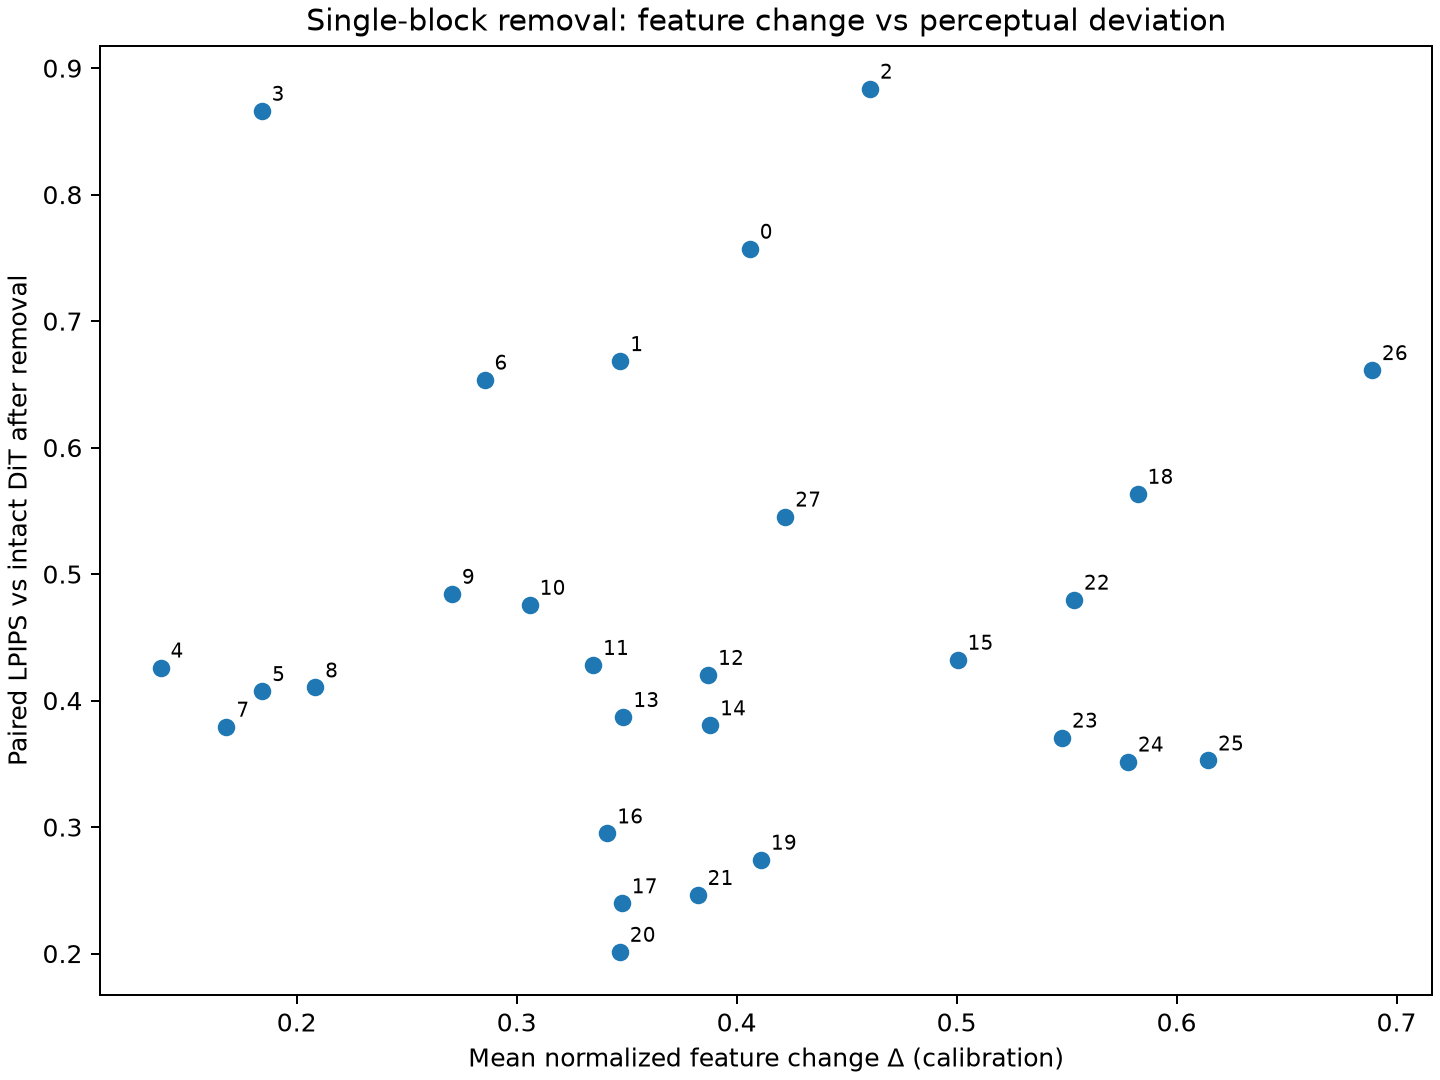

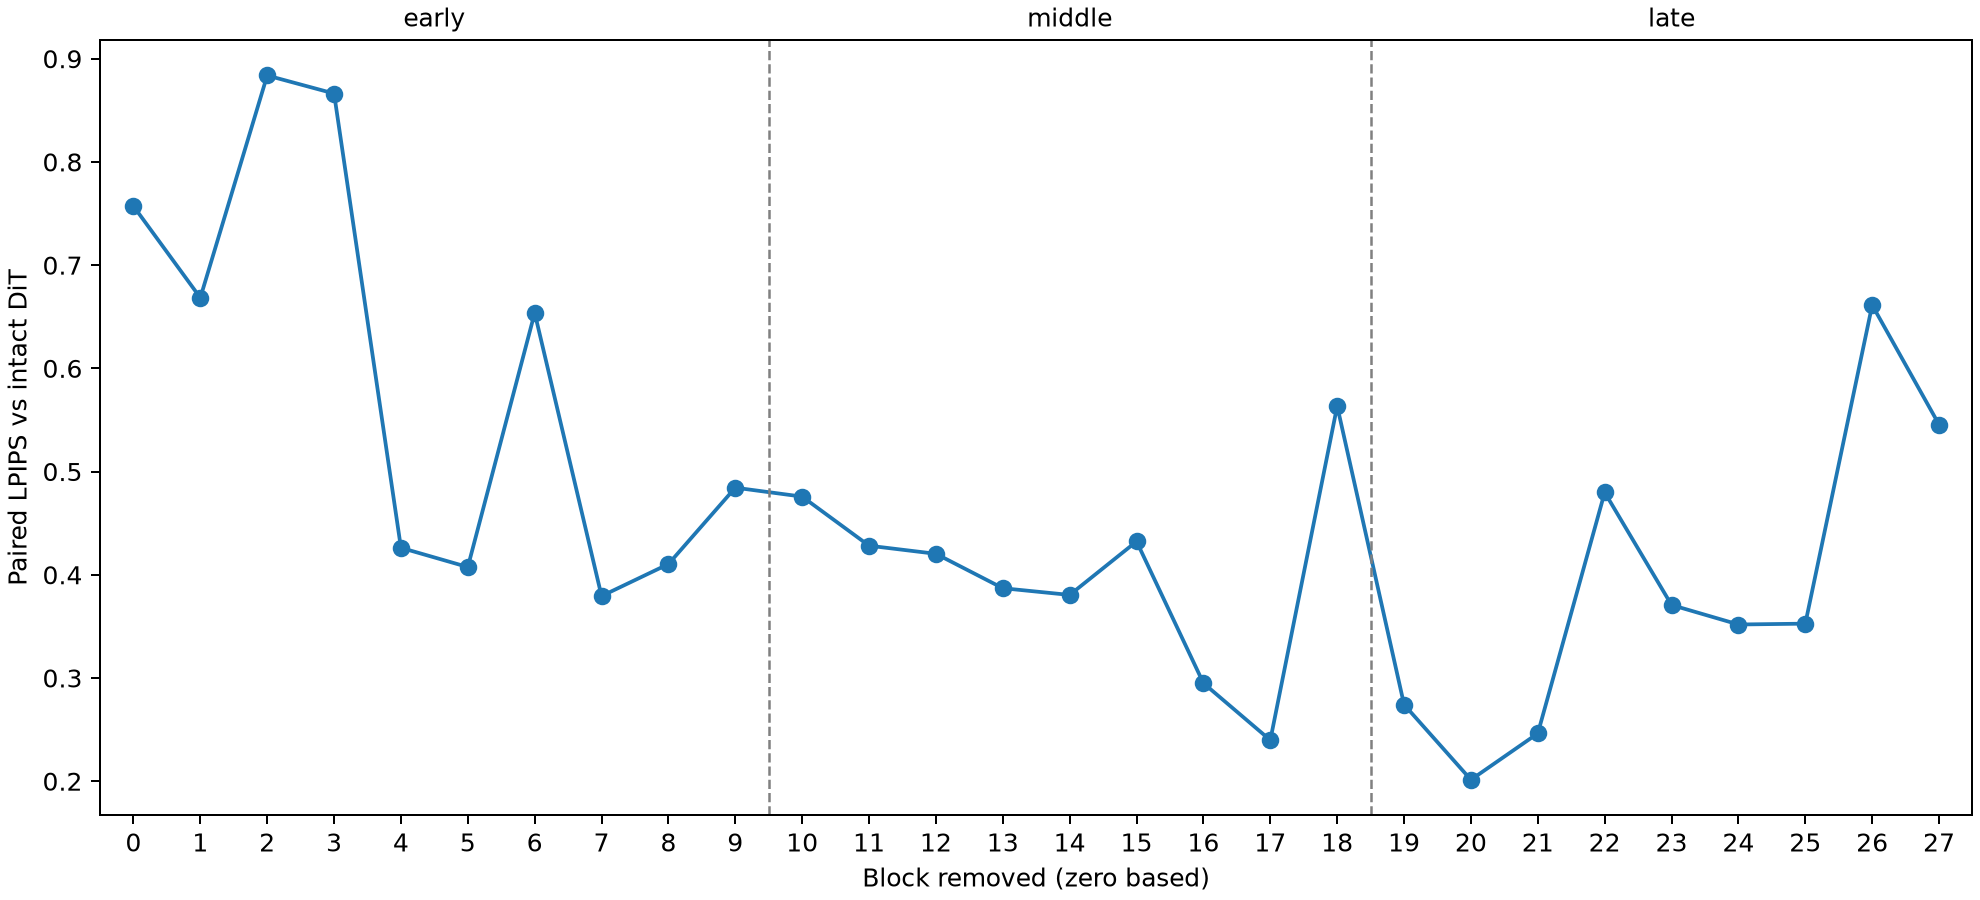

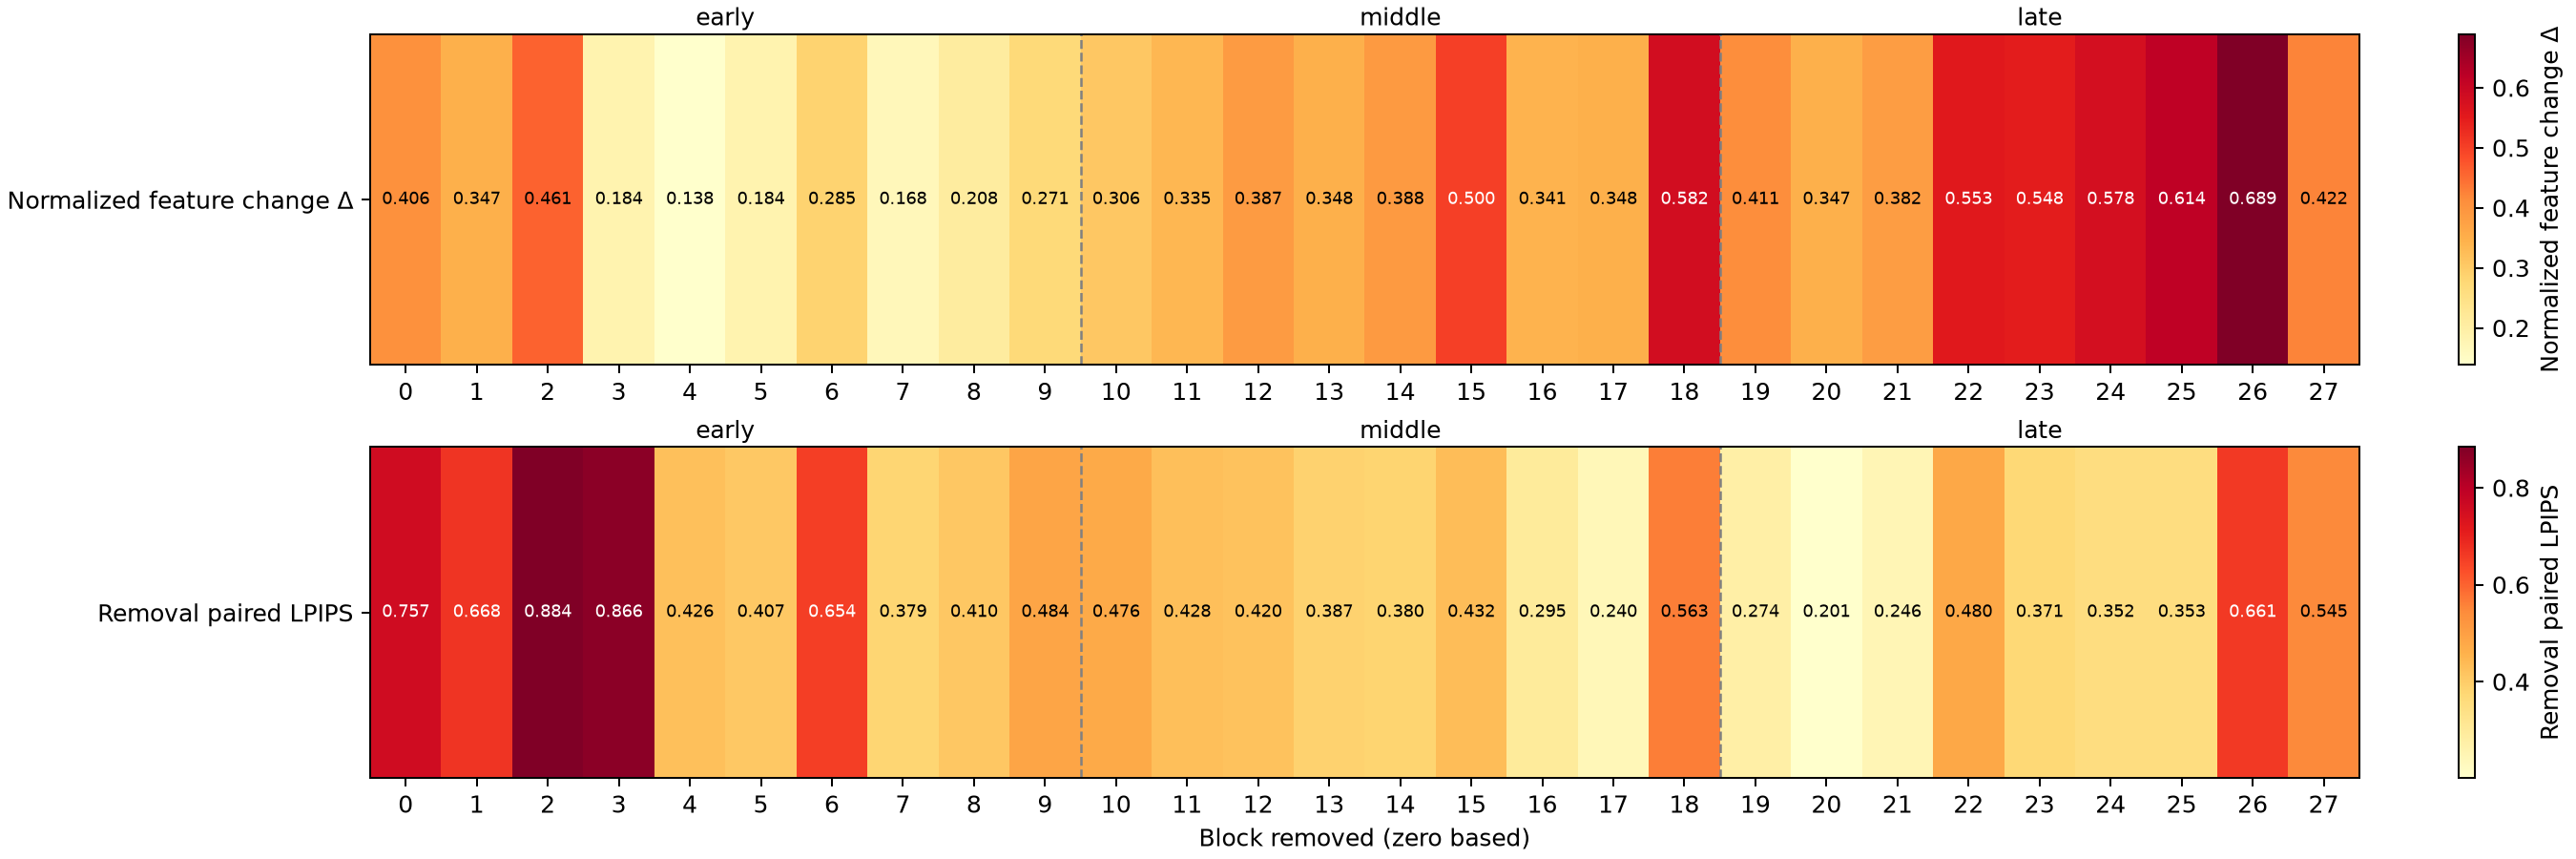

In [8]:
# REDRAW BLOCK ANALYSIS — saved sweep only; no inference.
from team_pipeline.ablation_report import write_ablation_report

SHOW_BLOCK_ANALYSIS = True
if SHOW_BLOCK_ANALYSIS:
    display(write_ablation_report(RUN_ROOT / "ablations/profile", RUN_ROOT / "ablations/sweep/validation"))
    for filename in ("feature_change_vs_lpips.png", "block_removal_lpips.png", "block_ablation_heatmap.png"):
        show_image(RUN_ROOT / "ablations/sweep/validation/analysis" / filename)


### 13.1 Top-R removal
Run the validation single-block sweep first. Highest-LPIPS-first ranking is frozen; no looping.
Inspect the LPIPS curve and exported adjacent slopes for a sharp rise; both CLIP scores are plotted too.


In [ ]:
# OPTIONAL TOP-R — includes intact R=0 baseline in plots.
RUN_TOP_R = True
TOP_R_COUNTS = list(range(1, 29))  # Use [1, 2, 4, 8, 12, 16, 20, 24, 28] for a smaller pilot.
if RUN_TOP_R:
    display(run_study(SimpleNamespace(output=RUN_ROOT, repo=REPO, study="topk",
                                     split="validation", counts=TOP_R_COUNTS, keep_checkpoints=KEEP_CHECKPOINTS)))
    show_image(RUN_ROOT / "ablations/topk/validation/analysis/top_r_metrics.png")


original: 1/20, 30.68 s
original: 2/20, 31.39 s
original: 3/20, 32.02 s
original: 4/20, 31.89 s
original: 5/20, 33.97 s
original: 6/20, 34.22 s
original: 7/20, 31.94 s
original: 8/20, 32.06 s
original: 9/20, 32.21 s
original: 10/20, 32.22 s
original: 11/20, 32.16 s
original: 12/20, 32.39 s
original: 13/20, 32.38 s
original: 14/20, 32.26 s
original: 15/20, 32.16 s
original: 16/20, 32.00 s
original: 17/20, 31.92 s
original: 18/20, 31.96 s
original: 19/20, 32.17 s
original: 20/20, 32.08 s
removal: 1/20, 30.74 s
removal: 2/20, 30.76 s
removal: 3/20, 30.78 s
removal: 4/20, 31.06 s
removal: 5/20, 31.11 s
removal: 6/20, 31.22 s
removal: 7/20, 31.02 s
removal: 8/20, 30.93 s
removal: 9/20, 30.94 s
removal: 10/20, 29.83 s
removal: 11/20, 30.55 s
removal: 12/20, 30.65 s
removal: 13/20, 30.88 s
removal: 14/20, 30.85 s
removal: 15/20, 30.71 s
removal: 16/20, 30.73 s
removal: 17/20, 30.62 s
removal: 18/20, 30.87 s
removal: 19/20, 30.91 s
removal: 20/20, 30.86 s
removal: 1/20, 29.49 s
removal: 2/20, 